<a href="https://colab.research.google.com/github/alwinbshaji/Data-Science/blob/main/Deeplearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Regression Model - King County House Price Prediction

In [1]:
import numpy as np
import pandas as pd

In [2]:
mydf = pd.read_csv('/content/drive/MyDrive/faith fahhhhh/kc_house_data.csv')
mydf

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21609,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21610,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21611,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21612,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [3]:
mydf.head(5)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000


In [4]:
mydf.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

EDA - exploratory data analysis

In [9]:
#print the size and shape of the daya using shape
print(mydf.shape)

#print the count of the data for all the columns( to find null)
print(mydf.count())

#to get more insights use describe()
print(mydf.describe())

#print all the cloumns data types
print(mydf.dtypes)

(21614, 21)
id               21614
date             21614
price            21614
bedrooms         21614
bathrooms        21614
sqft_living      21614
sqft_lot         21614
floors           21614
waterfront       21614
view             21614
condition        21614
grade            21614
sqft_above       21614
sqft_basement    21614
yr_built         21614
yr_renovated     21614
zipcode          21614
lat              21614
long             21614
sqft_living15    21614
sqft_lot15       21614
dtype: int64
                 id         price      bedrooms     bathrooms   sqft_living  \
count  2.161400e+04  2.161400e+04  21614.000000  21614.000000  21614.000000   
mean   4.580205e+09  5.400911e+05      3.370871      2.114798   2079.894189   
std    2.876534e+09  3.671190e+05      0.930050      0.770169    918.420011   
min    1.000102e+06  7.500000e+04      0.000000      0.000000    290.000000   
25%    2.123049e+09  3.219625e+05      3.000000      1.750000   1427.750000   
50%    3.904930e+0

Data Preprocessing/ data cleaning

In [12]:
#split and keep only the year value from the data coalumn
mydf['reg_year'] = mydf['date'].str[:4]

# eg. split this long value upto 4th index will get 2014
#convert the new column into integer
mydf['reg_year'] = mydf['reg_year'].astype('int')

#print all the cloumns
mydf.head(2)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,reg_year
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,2014
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014


In [15]:
cia =  mydf[['yr_built','yr_renovated','reg_year']].copy()
cia

,yr_built,yr_renovated,reg_year
0,1955,0,2014
1,1951,1991,2014
2,1933,0,2015
3,1965,0,2014
4,1965,0,2014
...,...,...,...
21609,2009,0,2014
21610,2014,0,2015
21611,2009,0,2014
21612,2004,0,2015


In [17]:
#we can add a new column called house age
#if yr_renovated isnot zero then age = re_year - yr_renocaated

#create a new column mydf[house_age] and fil lit with nan
mydf['house_age'] = np.nan
mydf.head(2)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,reg_year,house_age
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,NaN
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,NaN


In [ ]:
#using for loop , loop through each row check for condition
#and fill approrocate values for house_age
for i,j in enumerate(mydf['yr_renovated']):
  if (j==0):
    mydf['house_age'][i] = mydf['reg_year'][i] - mydf['yr_built'][i]
  else:
    mydf['house_age'][i] = mydf['reg_year'][i] - mydf['yr_renovated'][i]


In [20]:
mydf.head(2)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,reg_year,house_age
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,0,1955,0,98178,47.5112,-122.257,1340,5650,2014,59.0
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,400,1951,1991,98125,47.7210,-122.319,1690,7639,2014,23.0


In [21]:
#remove al the irrelated solumns in polace
mydf.drop(['id','lat','zipcode','long','date','yr_built','yr_renovated','reg_year'],axis=1,inplace=True)


In [22]:
mydf.head(2)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15,house_age
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1340,5650,59.0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1690,7639,23.0


In [23]:
mydf.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15,house_age
count,2.161400e+04,21614.000000,21614.000000,21614.000000,2.161400e+04,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000,21614.000000
mean,5.400911e+05,3.370871,2.114798,2079.894189,1.510650e+04,1.494286,0.007541,0.234293,3.409503,7.656843,1788.356528,291.537661,1986.523503,12768.096234,40.937309
std,3.671190e+05,0.930050,0.770169,918.420011,4.141961e+04,0.539987,0.086515,0.766301,0.650818,1.175440,828.087051,442.584799,685.388698,27303.599094,28.813029
min,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,399.000000,651.000000,-1.000000
25%,3.219625e+05,3.000000,1.750000,1427.750000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1490.000000,5100.000000,15.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.617500e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1840.000000,7620.000000,37.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068775e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,2360.000000,10083.000000,60.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,6210.000000,871200.000000,115.000000


In [26]:
#by describing we found that the house_age at somplace is <0
#so we haveto retain oly those values filyer those values and
#reasign that to the dataframe
mydf = mydf[mydf['house_age']>=0]
mydf.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15,house_age
count,2.108000e+04,21080.000000,21080.000000,21080.00000,2.108000e+04,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000,21080.000000
mean,5.365544e+05,3.361860,2.100889,2067.73444,1.532872e+04,1.481475,0.007638,0.236954,3.419734,7.637429,1775.026471,292.707970,1981.092884,12927.460816,41.975190
std,3.664097e+05,0.930268,0.767953,915.00783,4.187622e+04,0.534853,0.087061,0.770113,0.655607,1.174145,821.620358,443.556848,681.215049,27570.426850,28.418638
min,7.500000e+04,0.000000,0.000000,290.00000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,399.000000,651.000000,1.000000
25%,3.200000e+05,3.000000,1.500000,1420.00000,5.100000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1480.000000,5145.500000,17.000000
50%,4.499500e+05,3.000000,2.250000,1900.00000,7.680000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1550.000000,0.000000,1840.000000,7680.000000,38.000000
75%,6.390000e+05,4.000000,2.500000,2520.00000,1.080000e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2190.000000,562.500000,2350.000000,10125.000000,61.000000
max,7.700000e+06,33.000000,8.000000,13540.00000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,6210.000000,871200.000000,115.000000


Defining and comploling the model

In [28]:
mydf.head(2)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15,house_age
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1340,5650,59.0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1690,7639,23.0


In [31]:
#now our data is clean to be filtere into the model
#split the dataset into x and y - input adn output
x = mydf.drop(['price'],axis=1) #all columns except is the input
y = mydf['price'] #only the price column is the output

In [32]:
x

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,sqft_living15,sqft_lot15,house_age
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1340,5650,59.0
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1690,7639,23.0
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,2720,8062,82.0
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1360,5000,49.0
4,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1360,5000,49.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21609,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,1530,1509,5.0
21610,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,1830,7200,1.0
21611,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,1020,2007,5.0
21612,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,1410,1287,11.0


In [33]:
y

,price
0,221900.0
1,538000.0
2,180000.0
3,604000.0
4,604000.0
...,...
21609,360000.0
21610,400000.0
21611,402101.0
21612,400000.0


In [34]:
#define the keraas squential model
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [35]:
print(x.shape)

(21080, 14)


In [38]:
#initialze a sequential model object and add the layers
mymodel = keras.Sequential()
#since we have 14 columns we wil defune the input tlayer with 14 nodes
#with relu as the standard activation function
mymodel.add(layers.Dense(14,activation='relu'))
mymodel.add(layers.Dense(14,activation='relu'))
mymodel.add(layers.Dense(12,activation='relu'))
mymodel.add(layers.Dense(12,activation='relu'))
mymodel.add(layers.Dense(1)) # ouput layer

In [41]:
# compile the model with a loss function and optimizer
# for loss, as standard we use the MeanSquareError and optimizer we use adam
# the metric to be returned during training is Mean Square Error and Mean
mymodel.compile(loss='mse',optimizer='adam',metrics=['mse','mae'])



In [42]:
# Train the build the model using fit() function
# The historical metrics value will be returned back by the fit() fn
# we will save that into a history variable for future graph plotting
history = mymodel.fit(x,y,validation_split=0.33,batch_size=32,epochs=20)
# validation_split is the % split for testing, here we have 33% for testing
# batch_size - each batch will have 32 records out of 21600 records
# epochs - after one epoch, all the 21600 records will pass through the model
mymodel.summary()

Epoch 1/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 358863405056.0000 - mae: 467125.9688 - mse: 358863405056.0000 - val_loss: 331465097216.0000 - val_mae: 452850.7188 - val_mse: 331465097216.0000
Epoch 2/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 278931767296.0000 - mae: 381653.2188 - mse: 278931767296.0000 - val_loss: 221216325632.0000 - val_mae: 337801.3438 - val_mse: 221216325632.0000
Epoch 3/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 123053678592.0000 - mae: 212469.2500 - mse: 123053678592.0000 - val_loss: 72283930624.0000 - val_mae: 173728.6562 - val_mse: 72283930624.0000
Epoch 4/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 72471027712.0000 - mae: 170224.3438 - mse: 72471027712.0000 - val_loss: 68894621696.0000 - val_mae: 174943.1875 - val_mse: 68894621696.0000
Epoch 5/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 70398058496.0000 - mae: 167886.4219 - mse: 70398058496.0000 - val_loss: 68614250496.0000 - val_mae: 176654.8125 - val_mse: 6861425

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 14)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,469 (5.74 KB)

 Trainable params: 489 (1.91 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 980 (3.83 KB)

In [40]:
import matplotlib.pyplot as plt


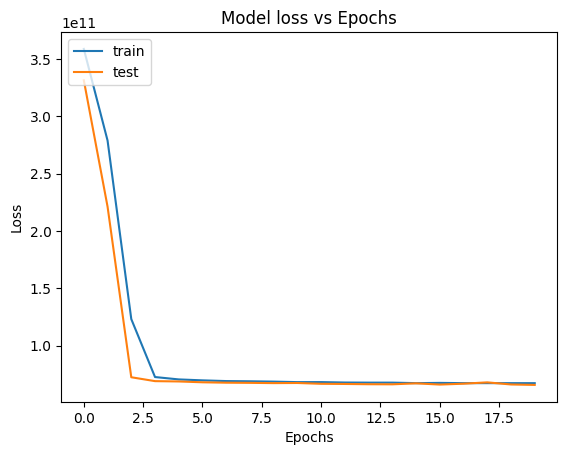

In [43]:
# we will plot a graph from the metric history availabe
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss vs Epochs')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['train','test'],loc='upper left')
plt.show()